<a href="https://colab.research.google.com/github/Tumisang-Precious/AI_for_Science_and_Engineering/blob/main/Week4_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO

# GitHub repository
owner = "onyekpeu"
repo = (
    "Data-on-one-dimensional-vertical-free-swelling-potential-of-soils-and-related-soil-properties-"
)

api_url = f"https://api.github.com/repos/{owner}/{repo}/git/trees/HEAD?recursive=1"

response = requests.get(api_url, timeout=30)
response.raise_for_status()

files = response.json().get("tree", [])

# Find downloadable CSV and Excel files
data_files = [
    item["path"] for item in files
    if item["path"].lower().endswith((".csv", ".xlsx", ".xls"))
]

print("Data files found:")
for file in data_files:
    print(file)

if not data_files:
    raise ValueError(
        "No CSV or Excel files were found. Check the repository URL "
        "and inspect the repository files manually."
    )

# Load the first available data file
file_path = data_files[0]
raw_url = (
    f"https://raw.githubusercontent.com/{owner}/{repo}/HEAD/{file_path}"
)

file_response = requests.get(raw_url, timeout=30)
file_response.raise_for_status()

if file_path.lower().endswith(".csv"):
    df = pd.read_csv(BytesIO(file_response.content))
else:
    df = pd.read_excel(BytesIO(file_response.content))

print("\nSelected file:", file_path)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Data files found:
Dataset.xlsx

Selected file: Dataset.xlsx
Dataset shape: (38, 16)


,Soil type,SP,G,Mc,e,γd,LL,PL,PI,USCS,Surcharge,A,Cc,Sc,OMC,MDD
0,NaN,%,-,%,-,kN/m3,%,%,%,-,kPa,-,%,%,%,kN/m3
1,Low platic clay (modified proctor compaction),10.5,2.83,8.6,0.62,18.601456,28,20,8,CL,1,0.4,21,54,12,19.4
2,Low platic clay (standard proctor compaction),8,2.83,12.6,0.5,20.9934,28,20,8,CL,1,0.4,21,54,12,19.4
3,Low platic clay (standard proctor compaction),5,2.83,16.5,0.56,20.684008,28,20,8,CL,1,0.4,21,54,12,19.4
4,Low plastic clay (modied proctor compaction),16.8,2.83,8,0.45,20.668655,28,20,8,CL,1,0.4,21,54,12,19.4



Column names:
['Soil type', 'SP', 'G', 'Mc', 'e', 'γd', 'LL', 'PL', 'PI', 'USCS', 'Surcharge', 'A', 'Cc', 'Sc', 'OMC', 'MDD']


In [2]:

def find_column(data, possible_names):
    normalized = {
        str(col).strip().lower().replace(" ", "").replace("_", ""): col
        for col in data.columns
    }

    for name in possible_names:
        key = name.lower().replace(" ", "").replace("_", "")
        if key in normalized:
            return normalized[key]

    raise KeyError(
        f"Could not find any of {possible_names}. "
        f"Available columns: {data.columns.tolist()}"
    )

column_map = {
    "PI": find_column(
        df, ["PI", "Plasticity Index", "Plasticity_Index"]
    ),
    "CC": find_column(
        df, ["CC", "Clay Content", "Clay_Content"]
    ),
    "Mc": find_column(
        df, ["Mc", "Moisture Content", "Initial Moisture Content"]
    ),
    "SP": find_column(
        df, ["SP", "Swell Percent", "Swelling Percentage",
             "Swell Percentage"]
    )
}

selected = df[list(column_map.values())].copy()
selected.columns = list(column_map.keys())

# Convert the selected columns to numerical values
for column in selected.columns:
    selected[column] = pd.to_numeric(
        selected[column], errors="coerce"
    )

print("Selected variables:")
display(selected.head())

print("\nMissing values per variable:")
print(selected.isna().sum())


Selected variables:


,PI,CC,Mc,SP
0,NaN,NaN,NaN,NaN
1,8.0,21.0,8.6,10.5
2,8.0,21.0,12.6,8.0
3,8.0,21.0,16.5,5.0
4,8.0,21.0,8.0,16.8



Missing values per variable:
PI    1
CC    1
Mc    1
SP    1
dtype: int64


In [3]:

# Calculate descriptive statistics for each variable
results = []

for column in selected.columns:
    values = selected[column].dropna()

    results.append({
        "Variable": column,
        "Valid observations": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Range": values.max() - values.min(),
        "Variance": values.var(ddof=1),
        "Standard deviation": values.std(ddof=1)
    })

statistics_table = pd.DataFrame(results).set_index("Variable")

display(statistics_table.round(4))


,Valid observations,Mean,Median,Minimum,Maximum,Range,Variance,Standard deviation
Variable,,,,,,,,
PI,37,24.1622,16.0,8.0,50.0,42.0,229.2508,15.1410
CC,37,27.6757,26.0,21.0,38.0,17.0,28.8363,5.3699
Mc,37,14.0973,13.9,7.9,24.0,16.1,20.0675,4.4797
SP,37,17.3459,17.7,3.2,34.4,31.2,69.1464,8.3154


In [4]:

# Keep only rows with both PI and SP available
paired = selected[["PI", "SP"]].dropna()

covariance = paired["PI"].cov(paired["SP"])
correlation = paired["PI"].corr(paired["SP"])

print("Number of paired observations:", len(paired))
print(f"Covariance (PI and SP): {covariance:.4f}")
print(f"Pearson correlation (PI and SP): {correlation:.4f}")


Number of paired observations: 37
Covariance (PI and SP): 96.6618
Pearson correlation (PI and SP): 0.7677


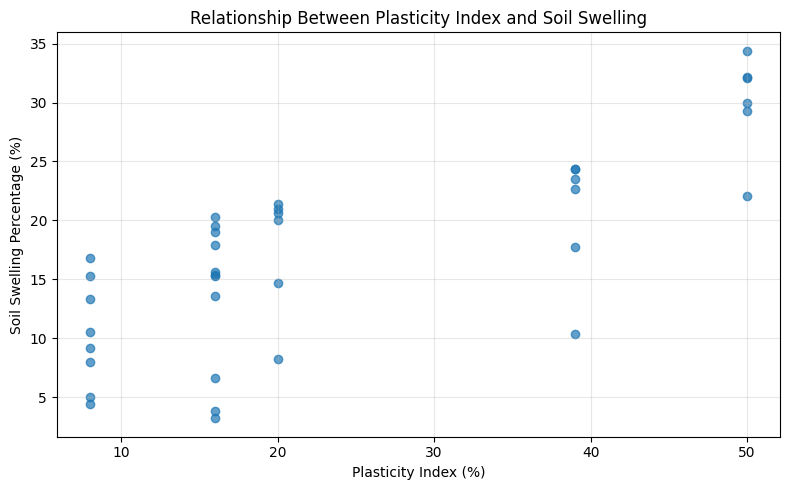

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(
    paired["PI"],
    paired["SP"],
    alpha=0.7
)

plt.xlabel("Plasticity Index (%)")
plt.ylabel("Soil Swelling Percentage (%)")
plt.title("Relationship Between Plasticity Index and Soil Swelling")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 1. What do the statistics tell you about the data?

The mean represents the average value of each soil property, while the median represents its middle value. A substantial difference between the mean and median may indicate a skewed distribution or the influence of extreme observations. The range describes the difference between the minimum and maximum values. Variance and standard deviation describe how widely the observations are dispersed around the mean. A larger standard deviation indicates greater variability in the measured property.

### 2. What does the correlation tell you?

A positive coefficient indicates that higher plasticity index values tend to occur with higher swelling percentages; a negative coefficient indicates an inverse linear relationship. A coefficient close to zero indicates little linear association, although a nonlinear relationship may still exist.

Covariance indicates whether the two variables tend to vary in the same or opposite directions, but its magnitude depends on their measurement scales. Correlation is easier to interpret because it ranges from -1 to +1.

### 3. Does correlation necessarily mean causation?

No. Correlation does not establish that one variable causes another. Soil swelling can also depend on clay mineralogy, moisture conditions, surcharge pressure, density, soil structure and testing conditions. The observed relationship may be influenced by these factors or by differences between the soil samples. Further geotechnical investigation and appropriately designed modelling are needed before drawing causal conclusions.

Input → Function/Model → Output
For your project, the simplest mathematical expression is:
\[
\boxed{\text{PI} \xrightarrow{f} \widehat{\text{SP}}}
\]

Where:
- \(\text{PI}\) = plasticity index, the input.
- \(f\) = a mathematical function or trained machine-learning model.
- \(\widehat{\text{SP}}\) = predicted soil swelling percentage, the output.

In [8]:
from sklearn.linear_model import LinearRegression

# Prepare the data
X = paired[["PI"]]
y = paired["SP"]

# Fit a simple linear regression model
model = LinearRegression()
model.fit(X, y)

slope = model.coef_[0]
intercept = model.intercept_
r_squared = model.score(X, y)

print(f"Slope (beta_1): {slope:.4f}")
print(f"Intercept (beta_0): {intercept:.4f}")
print(f"R-squared: {r_squared:.4f}")

Slope (beta_1): 0.4216
Intercept (beta_0): 7.1582
R-squared: 0.5894


Based on the linear regression fit, we can write the relationship as a concrete mathematical expression:

$$\widehat{\text{SP}} = 0.4216 \times \text{PI} + 7.1582$$

Where:
- $\widehat{\text{SP}}$ is the predicted Soil Swelling Percentage (%).
- $\text{PI}$ is the Plasticity Index (%).
- $0.4216$ is the slope coefficient, representing the expected increase in swelling percentage for each 1% increase in the plasticity index.
- $7.1582$ is the intercept, representing the baseline swelling percentage when the plasticity index is zero.